# 03 Algoritmo genético: ajuste, comparación y pruebas estadísticas (Entrega 4)

1. **Ajuste del GA** (rejilla N × pc × pm) con semillas de ajuste y prueba de Kruskal-Wallis.
2. **Comparación** GA vs GRASP vs voraz vs aleatoria con el mismo presupuesto, semillas distintas a las del ajuste: Kruskal-Wallis, Mann-Whitney con Holm y tamaño de efecto de Cliff.
3. **Validación cruzada por organización** (5 pliegues): Friedman y Wilcoxon pareado sobre pliegues reales.

Pon `RAPIDO = True` para una prueba de humo (minutos); `False` para la corrida final.

In [16]:
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats as sp

import metric_extraction.rules as rl
import metric_extraction.stats as st
from metric_extraction.download import safe_name
from metric_extraction.evidence import read_body
from metric_extraction.evaluator import Instance
from metric_extraction.gold import gold_tuples
from metric_extraction.genetic import GAParams
from metric_extraction.experiments import compare, tune_ga, cross_validate, group_folds, mean_trace

RAPIDO = False
BUDGET   = 300 if RAPIDO else 3000
N_TUNE   = 3   if RAPIDO else 10      # semillas de ajuste: 1000, 1001, ...
N_SEEDS  = 5   if RAPIDO else 30      # semillas finales: 0, 1, ...
N_CV     = 2   if RAPIDO else 10
OUT = Path("../results/e4"); OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/HFCO2_2026.csv", sep=",")
ref = df[df["performance_metrics"].notna()]
cards = []
for _, r in ref.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    g = gold_tuples(r["performance_metrics"])
    if p.exists() and g:
        cards.append({"id": r["modelId"], "tag": str(r["pipeline_tag"]), "gold": g, "text": read_body(p)})
cat = rl.build_catalog(); n = len(cat)
t0 = time.time(); inst = Instance(cards, cat)
print(f"{len(cards)} fichas, {n} reglas, precálculo {time.time()-t0:.0f}s")

390 fichas, 27 reglas, precálculo 71s


## 1. Ajuste de parámetros del GA

Rejilla N ∈ {30, 50, 100}, pc ∈ {0,7; 0,9}, pm ∈ {0,1; 0,2; 0,4}; K=5. Las semillas de ajuste (1000+) no se usan en la comparación final.

In [17]:
tune = tune_ga(inst, K=5, budget=BUDGET, seeds=range(1000, 1000 + N_TUNE))
tune.to_csv(OUT / "ajuste_ga.csv", index=False)
tune["cfg"] = tune.apply(lambda r: f"N={int(r.N)} pc={r.pc} pm={r.pm}", axis=1)
resumen = tune.groupby("cfg").f_train.agg(["median", "mean", "std"]).sort_values("median", ascending=False)
display(resumen.round(4))
kw = st.kruskal({k: g.f_train.values for k, g in tune.groupby("cfg")})
print("Kruskal-Wallis entre configuraciones:", kw)
# efecto de cada parámetro por separado
for par in ("N", "pc", "pm"):
    print(par, st.kruskal({str(k): g.f_train.values for k, g in tune.groupby(par)}))

{'N': 30, 'pc': 0.7, 'pm': 0.1} mediana=0.3399
{'N': 30, 'pc': 0.7, 'pm': 0.2} mediana=0.3328
{'N': 30, 'pc': 0.7, 'pm': 0.4} mediana=0.3401
{'N': 30, 'pc': 0.9, 'pm': 0.1} mediana=0.3401
{'N': 30, 'pc': 0.9, 'pm': 0.2} mediana=0.3401
{'N': 30, 'pc': 0.9, 'pm': 0.4} mediana=0.3399
{'N': 50, 'pc': 0.7, 'pm': 0.1} mediana=0.3401
{'N': 50, 'pc': 0.7, 'pm': 0.2} mediana=0.3401
{'N': 50, 'pc': 0.7, 'pm': 0.4} mediana=0.3401
{'N': 50, 'pc': 0.9, 'pm': 0.1} mediana=0.3401
{'N': 50, 'pc': 0.9, 'pm': 0.2} mediana=0.3399
{'N': 50, 'pc': 0.9, 'pm': 0.4} mediana=0.3399
{'N': 100, 'pc': 0.7, 'pm': 0.1} mediana=0.3401
{'N': 100, 'pc': 0.7, 'pm': 0.2} mediana=0.3401
{'N': 100, 'pc': 0.7, 'pm': 0.4} mediana=0.3401
{'N': 100, 'pc': 0.9, 'pm': 0.1} mediana=0.3401
{'N': 100, 'pc': 0.9, 'pm': 0.2} mediana=0.3401
{'N': 100, 'pc': 0.9, 'pm': 0.4} mediana=0.3401


,median,mean,std
cfg,,,
N=100 pc=0.7 pm=0.1,0.3401,0.3394,0.0023
N=100 pc=0.7 pm=0.2,0.3401,0.3401,0.0000
N=100 pc=0.7 pm=0.4,0.3401,0.3401,0.0000
N=100 pc=0.9 pm=0.1,0.3401,0.3391,0.0029
N=100 pc=0.9 pm=0.2,0.3401,0.3401,0.0000
N=100 pc=0.9 pm=0.4,0.3401,0.3401,0.0000
N=30 pc=0.9 pm=0.1,0.3401,0.3343,0.0135
N=30 pc=0.7 pm=0.4,0.3401,0.3350,0.0108
N=50 pc=0.7 pm=0.1,0.3401,0.3384,0.0035


Kruskal-Wallis entre configuraciones: {'H': 37.42422813354063, 'p': 0.002946800487166859, 'k': 18, 'n': 180}
N {'H': 26.056388804537047, 'p': 2.197490781767362e-06, 'k': 3, 'n': 180}
pc {'H': 0.05691414190178151, 'p': 0.8114414728496295, 'k': 2, 'n': 180}
pm {'H': 0.054911612433443, 'p': 0.972917678516402, 'k': 3, 'n': 180}


Elige la configuración con mejor mediana (o la más barata si no hay diferencia significativa) y fíjala aquí:

In [18]:
mejor = resumen.index[0]; print("mejor por mediana:", mejor)
row = tune[tune.cfg == mejor].iloc[0]
GA = GAParams(N=int(row.N), pc=float(row.pc), pm=float(row.pm))
print(GA)

mejor por mediana: N=100 pc=0.7 pm=0.1
GAParams(N=100, pc=0.7, pm=0.1, k_t=3, elite=2, rho=0.2, alpha=0.3, G=15, seed_share=0.25)


## 2. Comparación GA vs GRASP vs líneas base

Mismo presupuesto, K=5 y K=6, catálogo completo, sin límite de tiempo (como la Tabla de catálogo completo de la Entrega 3). Para repetir con tiempo limitado pon `TMAX = 0.080`.

In [19]:
TMAX = None
res, traces = {}, {}
for K in (5, 6):
    res[K], traces[K] = compare(inst, K, BUDGET, range(N_SEEDS), tmax=TMAX, ga=GA)
    res[K].to_csv(OUT / f"comparacion_K{K}.csv", index=False)
allres = pd.concat(res.values())
display(allres.groupby(["K", "method"]).agg(mediana=("macro_F1", "median"), media=("macro_F1", "mean"),
        sd=("macro_F1", "std"), P=("P", "mean"), t_ms=("time_ms", "mean"), evals=("evals", "mean")).round(4))

K=5 Voraz      mediana=0.3401 media=0.3401
K=5 Aleatoria  mediana=0.2918 media=0.2935
K=5 GRASP      mediana=0.3401 media=0.3401
K=5 GA         mediana=0.3401 media=0.3395
K=6 Voraz      mediana=0.3572 media=0.3572
K=6 Aleatoria  mediana=0.3149 media=0.3125
K=6 GRASP      mediana=0.3572 media=0.3572
K=6 GA         mediana=0.3572 media=0.3568


mediana   media      sd       P     t_ms      evals
K method                                                        
5 Aleatoria   0.2918  0.2935  0.0165  0.9947  88.6565  2393.9000
  GA          0.3401  0.3395  0.0023  0.9918  92.0102  2392.9667
  GRASP       0.3401  0.3401  0.0000  0.9915  93.1350  3088.7667
  Voraz       0.3401  0.3401  0.0000  0.9915  93.1350   367.0000
6 Aleatoria   0.3149  0.3125  0.0147  0.9945  93.0286  2516.9333
  GA          0.3572  0.3568  0.0017  0.9918  99.2344  2511.5333
  GRASP       0.3572  0.3572  0.0000  0.9915  99.7527  3145.8333
  Voraz       0.3572  0.3572  0.0000  0.9915  99.7527   499.0000

In [20]:
rows = []
for K, d in res.items():
    est = {m: g.macro_F1.values for m, g in d.groupby("method") if m != "Voraz"}   # estocásticos
    kw = st.kruskal(est)
    print(f"K={K} Kruskal-Wallis (Aleatoria, GRASP, GA): H={kw['H']:.2f} p={kw['p']:.4g}")
    for r in st.pairwise_mannwhitney(est):
        rows.append({"K": K, **r})
    voraz = d[d.method == "Voraz"].macro_F1.iloc[0]
    for m, v in est.items():           # cada método estocástico frente al valor fijo del voraz
        x = v - voraz
        p = 1.0 if np.allclose(x, 0) else sp.wilcoxon(x).pvalue
        rows.append({"K": K, "A": m, "B": "Voraz (valor fijo)", "mediana_A": float(np.median(v)),
                     "mediana_B": float(voraz), "p": float(p), "cliffs_delta": float((v > voraz).mean() - (v < voraz).mean()),
                     "p_holm": np.nan})
pruebas = pd.DataFrame(rows); pruebas.to_csv(OUT / "pruebas_comparacion.csv", index=False)
display(pruebas.round(4))

K=5 Kruskal-Wallis (Aleatoria, GRASP, GA): H=77.62 p=1.397e-17
K=6 Kruskal-Wallis (Aleatoria, GRASP, GA): H=78.63 p=8.41e-18


,K,A,B,mediana_A,mediana_B,U,p,cliffs_delta,p_holm
0,5,Aleatoria,GA,0.2918,0.3401,0.0,0.0000,-1.0000,0.0000
1,5,Aleatoria,GRASP,0.2918,0.3401,0.0,0.0000,-1.0000,0.0000
2,5,GA,GRASP,0.3401,0.3401,375.0,0.0215,-0.1667,0.0215
3,5,Aleatoria,Voraz (valor fijo),0.2918,0.3401,NaN,0.0000,-1.0000,NaN
4,5,GA,Voraz (valor fijo),0.3401,0.3401,NaN,0.0384,-0.1667,NaN
5,5,GRASP,Voraz (valor fijo),0.3401,0.3401,NaN,1.0000,0.0000,NaN
6,6,Aleatoria,GA,0.3149,0.3572,0.0,0.0000,-1.0000,0.0000
7,6,Aleatoria,GRASP,0.3149,0.3572,0.0,0.0000,-1.0000,0.0000
8,6,GA,GRASP,0.3572,0.3572,390.0,0.0419,-0.1333,0.0419
9,6,Aleatoria,Voraz (valor fijo),0.3149,0.3572,NaN,0.0000,-1.0000,NaN


/home/juanfgallo/Documentos/projects/professional/magister/semesterIII/methaheuristics/src/metric_extraction/experiments.py:118: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.vstack(curves), axis=0) if curves else np.full(len(grid), np.nan)
/home/juanfgallo/Documentos/projects/professional/magister/semesterIII/methaheuristics/src/metric_extraction/experiments.py:118: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.vstack(curves), axis=0) if curves else np.full(len(grid), np.nan)


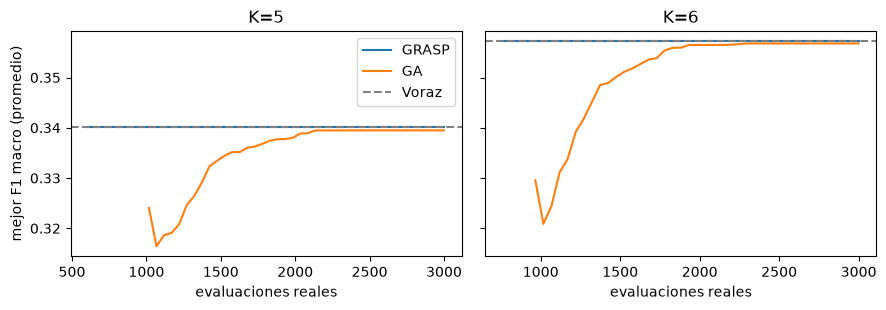

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
grid = np.linspace(0, BUDGET, 60)
for ax, K in zip(axs, (5, 6)):
    for m in ("Aleatoria", "GRASP", "GA"):
        if m == "Aleatoria":
            continue
        ax.plot(grid, mean_trace(traces[K], m, grid), label=m)
    ax.axhline(res[K][res[K].method == "Voraz"].macro_F1.iloc[0], ls="--", c="gray", label="Voraz")
    ax.set_title(f"K={K}"); ax.set_xlabel("evaluaciones reales")
axs[0].set_ylabel("mejor F1 macro (promedio)"); axs[0].legend()
plt.tight_layout(); plt.savefig(OUT / "convergencia_ga_grasp.png", dpi=200); plt.show()

## 3. Validación cruzada por organización

Cada pliegue es un bloque real, por lo que aquí sí corresponde Friedman y Wilcoxon pareado. Se agrega por pliegue la mediana sobre semillas.

In [22]:
folds = group_folds(cards, k=5); print([len(f) for f in folds])
cv = cross_validate(inst, 5, BUDGET, range(N_CV), folds, tmax=TMAX, ga=GA)
cv.to_csv(OUT / "validacion_cruzada_ga.csv", index=False)
piv = cv.groupby(["fold", "method"]).test_macro_F1.median().unstack()[["Voraz", "Aleatoria", "GRASP", "GA"]]
display(piv.round(4)); print(piv.mean().round(4).to_dict())
fr = st.friedman(piv.values); print("Friedman:", fr, "orden:", list(piv.columns))
pw = pd.DataFrame(st.pairwise_wilcoxon({m: piv[m].values for m in piv})); pw.to_csv(OUT / "pruebas_cv.csv", index=False)
display(pw.round(4))
print("Con 5 pliegues el menor p posible de Wilcoxon bilateral es 0,0625: no puede ser significativo.")

[236, 39, 39, 38, 38]
pliegue 0 listo (236 fichas de prueba)
pliegue 1 listo (39 fichas de prueba)
pliegue 2 listo (39 fichas de prueba)
pliegue 3 listo (38 fichas de prueba)
pliegue 4 listo (38 fichas de prueba)


method,Voraz,Aleatoria,GRASP,GA
fold,,,,
0,0.5384,0.5384,0.5384,0.5384
1,0.2430,0.2430,0.2430,0.2430
2,0.2059,0.1568,0.2059,0.2059
3,0.3678,0.3216,0.3678,0.3678
4,0.4020,0.3166,0.4020,0.4020


{'Voraz': 0.3514, 'Aleatoria': 0.3153, 'GRASP': 0.3514, 'GA': 0.3514}
Friedman: {'chi2': 8.999999999999986, 'p': 0.029290886534888358, 'mean_rank': [2.2, 3.4, 2.2, 2.2], 'blocks': 5} orden: ['Voraz', 'Aleatoria', 'GRASP', 'GA']


,A,B,mediana_dif,IC95_lo,IC95_hi,W,p,cliffs_delta,A_gana,B_gana,empates,p_holm
0,Voraz,Aleatoria,0.0462,0.0000,0.0854,0.0,0.25,0.2,3,0,2,1.0
1,Voraz,GRASP,0.0000,0.0000,0.0000,0.0,1.00,0.0,0,0,5,1.0
2,Voraz,GA,0.0000,0.0000,0.0000,0.0,1.00,0.0,0,0,5,1.0
3,Aleatoria,GRASP,-0.0462,-0.0854,0.0000,0.0,0.25,-0.2,0,3,2,1.0
4,Aleatoria,GA,-0.0462,-0.0854,0.0000,0.0,0.25,-0.2,0,3,2,1.0
5,GRASP,GA,0.0000,0.0000,0.0000,0.0,1.00,0.0,0,0,5,1.0


Con 5 pliegues el menor p posible de Wilcoxon bilateral es 0,0625: no puede ser significativo.


## 4. Mejores configuraciones halladas

In [23]:
display(allres.sort_values("macro_F1", ascending=False).groupby(["K", "method"]).head(1)[
    ["K", "method", "macro_F1", "P", "R", "time_ms", "k", "theta", "rules"]].round(4))

,K,method,macro_F1,P,R,time_ms,k,theta,rules
80,6,GRASP,0.3572,0.9915,0.6655,99.7527,6,1000.0,row:at_k > inline:clf_avg > inline:rank > colu...
91,6,GA,0.3572,0.9915,0.6655,99.7527,6,1000.0,inline:clf_basic > inline:rouge > column:clf_b...
24,6,Voraz,0.3572,0.9915,0.6655,99.7527,6,100.0,column:clf_basic > row:at_k > inline:rouge > i...
16,5,Voraz,0.3401,0.9915,0.6647,93.1350,5,100.0,column:clf_basic > row:at_k > inline:rouge > i...
60,5,GRASP,0.3401,0.9915,0.6647,93.1350,5,100.0,inline:clf_basic > column:clf_basic > row:at_k...
112,5,GA,0.3401,0.9915,0.6647,93.1350,5,100.0,row:at_k > inline:rouge > inline:rank > inline...
57,6,Aleatoria,0.3399,0.9927,0.6645,93.2471,6,100.0,row:at_k > column:clf_basic > inline:clf_basic...
40,5,Aleatoria,0.3197,0.9936,0.7055,94.0811,5,1.0,inline:clf_basic > inline:sim > column:clf_bas...
